# KQC Shaping — one Swissmon with two Purcell-filtered λ/4 resonators (Quantcore PDK rebuild)

**What the chip is.** KQCircuits' `chips/shaping.py` (class `Shaping`, default parameters `tunable = False`, chip
name "CTest"; © IQM Finland Oy, GPL-3.0, <https://github.com/iqm-finland/KQCircuits>; local copy
`other-libs/KQCircuits-main/.../kqcircuits/chips/shaping.py`; spec `docs/designs/kqc/test_chips.md`, row
*Shaping*). A Swissmon ("Finnmon") at (4000, 5000) µm, rotated 270°, with a charge line from WN and a flux line from
WS. Its coupler 0 (up) feeds the **readout** chain and its coupler 2 (down) the mirrored **shaping** chain. Each
chain is a λ/4 resonator drawn as straight → T → meander → T → shorted stub (KQC segment targets "from qubit to
shorted end" 611.586 / 1834.76 / 611.586 µm, and 634.71 / 1904.13 / 634.71 µm for the shaping chain), with a drive
gap capacitor on the first T (input from NW / SW) and a gap capacitor J on the second T into a λ/4 **Purcell
filter** (T → shorted stub one way, meander → κ interdigital capacitor → output EN / ES the other; targets
3158.32 / 789.581 and 3253.65 / 813.413 µm "from output to shorted end").

This notebook **rebuilds** that chip with our components, routes, netlist and LOM on the Quantcore PDK — not a
replica. We distribute the rebuild under GPL-3.0.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` | same 10 × 10 mm (the SMA8 launchers sit on its edges), Quantcore die frame, device ID "CTest" |
| launchers | SMA8, all eight (NE and SE carry nothing with `tunable = False`), `launcher_indent` 800 µm | SMA8, indent **880 µm** from the PDK pad rule (outer etch `frame.pad_edge` = 100 µm, 80 µm further in) |
| substrate | silicon εr 11.45 (KQC simulation default) | sapphire 650 µm, εr 10.25 |
| junction | KQC Manhattan SQUID (assumed L_J 12 nH, C_J 2 fF) | Quantcore trilayer SQUID, 2 × 0.25 × 0.6 µm, R_n 45 kΩ in parallel, L_J 6.73 nH, C_J 15 fF |
| cheese | KQC's whole-area ground grid (`with_grid`, in KQC's mask builds) | **the original wins:** KQC's grid (`with_grid=True`), so no PDK band |
| elements, positions, routes | — | kept: every KQC element with the source's parameters, positions and orientations; every straight with KQC's length formula; the launcher legs from the launcher ports |
| placement | centred | centred (checked below) |

**Kept exactly (same KQC cells, parameters and positions):** the `Swissmon` with KQC's arm, gap and coupler
lists; the six `WaveguideCoplanarSplitter`s (lengths 61/61/31 µm, ports right/left/bottom) placed as KQC places them
(T a: its port at the end of the first straight; T b: at the meander end; T c: snapped to capacitor J); the six
`FingerCapacitorSquare`s from KQC's `cap_params` (J gap 37.5 / 36.8 µm, κ interdigital 4 × 67.9 / 71.5 µm, drive
gap 36.2 µm), snapped port `a` to the T's as KQC aligns them; the charge line (6 µm open end), flux line, drive lines
and output lines along KQC's paths.

**Substituted:** KQC's four `Meander` cells (start, end, length, `meanders` = 2 / 3) are CPW routes T ↔ T (and T ↔ κ
capacitor, merged with the 400 µm Purcell leg) whose waypoints are the centre line KQC's `Meander` computes for the
same arguments (built in a scratch layout). Two reasons: (1) as a separate `Meander` instance the LOM would make each
one a λ/2 bus between the two T's, not part of the λ/4; (2) a Designer `meander` route also is a λ/2 bus and would
not reproduce KQC's shape. The meander leaves the T after 115 µm (150 µm for the Purcell meander), shorter than the
router's port stub plus a bend (2r = 200 µm), so these routes take `r = 10` µm for the router's port stubs and draw
with KQC's r = 100 µm (`params={"r": 100}`); the path is KQC's, which needs only 100 µm before each bend.

**LOM approximation (stated):** the builder makes each chain's routes one λ/4 `TLres` of the summed route length
(the wires join it to its coupler end) and attaches the drive and J capacitors there, i.e. at the open end, not at
their taps. The T's arms are not counted (≈ 300 µm per resonator, table in step 9), and the tapped coupling is
overestimated. The numbers are therefore rough: the mode structure (qubit, two readouts, two Purcell filters) is
right, the couplings are not to be trusted.

The notebook walks through the build step by step: setup and the PDK → die and frame → launchers → components →
routes → DRC → netlist → LOM simulation → FEM jobs → results back → one design change → fab export →
snapshots → summary.

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; `True` solves the jobs in a new batch AEDT
2024 R1 (if installed). `FULL_FAB = False` skips the fab-only corner rounding in the fab step (the KQC grid has ≈ 0.8 M holes on 1/0 and 3/0) (`qcc mask` writes the full file).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from kqcircuits.pya_resolver import pya

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc/test_chips")                 # design JSON + final snapshots
STEPS = Path("build/snapshots/shaping")  # step-by-step snapshots (build/ is not kept in the repo)

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The junction from the PDK rule.** KQC draws a SQUID in the Swissmon. `trilayer_junction` turns it into the
Quantcore trilayer SQUID: two junctions whose straight finger is KQC's `junction_width` (the bent finger stays at
the PDK 0.6 µm). With the nominal L_J (6.73 nH, the 0.5 × 0.6 µm junction at R_n 45 kΩ) as the SQUID's parallel
total, each junction is 0.25 × 0.6 µm. `JJ_PARAMS` go on the cell, `JUNCTION` (L_J, C_J) is what the LOM and the
FEM junction ports use.

In [4]:
LJ_PDK = trilayer_junction("Swissmon")[1]["Lj_nH"]          # PDK nominal L_J (0.5 × 0.6 µm junction, R_n 45 kΩ)
JJ_PARAMS, JUNCTION = trilayer_junction("Swissmon", lj_nH=LJ_PDK, squid=True)
print("cell parameters:", JJ_PARAMS)
print("LOM junction:   ", JUNCTION)

cell parameters: {'junction_type': 'Quantcore Squid', 'junction_width': 0.25}
LOM junction:    {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


## 3 · The die and its frame

`Designer(...)` starts the chip: the 10 × 10 mm box, all eight SMA8 launchers (KQC's default names NW, NE, EN, ES,
SE, SW, WS, WN) and the chip name "CTest" (the device ID). `with_grid=True` asks for KQC's whole-area ground grid
(the original's cheese): the PDK band is then not added. The frame is the PDK default (L dicing markers 1000/0,
3 × 3 alignment grids 1001/0, boundary 100/0); KQC's own `ChipFrame` is not drawn.

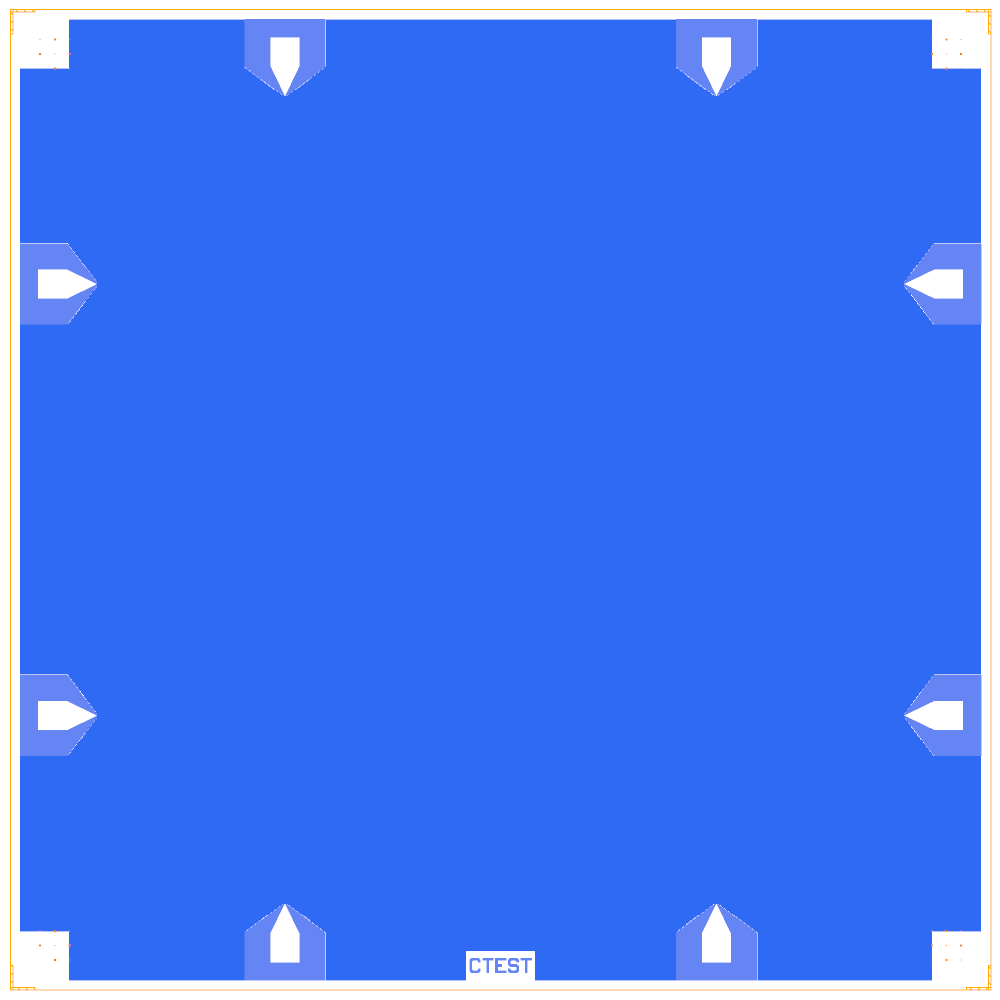

In [5]:
d = Designer("shaping", box=(0, 0, 10000, 10000), launchers="SMA8", chip={"name_chip": "CTest", "with_grid": True},
             live=LIVE)
snap(d, STEPS / "1_die.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420);

## 4 · Launchers and the pad rule

**PDK rule:** a launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge. For SMA8 (RF launcher:
300 µm taper + 300 µm pad + 180 µm frame gap) the Designer sets `launcher_indent` = 100 + 300 + 300 + 180 =
**880 µm** (KQC: 800 µm). Every line below starts at a launcher port or at a waypoint taken from one, so the 80 µm
shift needs no other change.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| chip.NW | launcher port | n | port 880 µm in (indent from the rule) | ✓ |
| chip.NE | launcher port | n | port 880 µm in (indent from the rule) | ✓ |
| chip.EN | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.ES | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.SE | launcher port | s | port 880 µm in (indent from the rule) | ✓ |
| chip.SW | launcher port | s | port 880 µm in (indent from the rule) | ✓ |
| chip.WS | launcher port | w | port 880 µm in (indent from the rule) | ✓ |
| chip.WN | launcher port | w | port 880 µm in (indent from the rule) | ✓ |

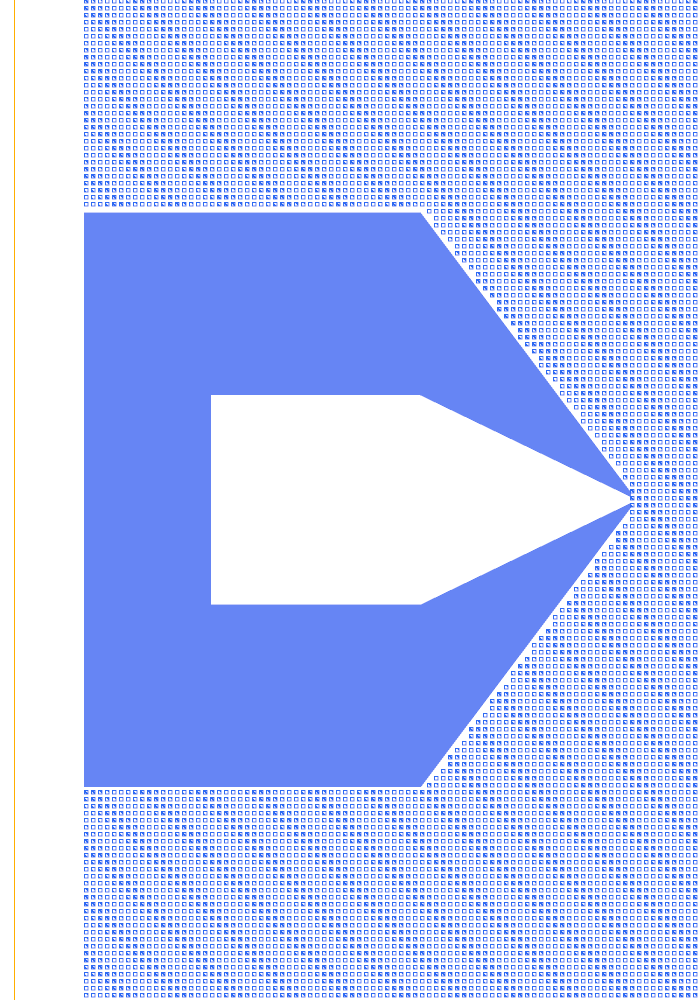

In [6]:
display(Markdown(pads_md(d)))
x, y = port_xy(d, "chip.WN")
snap(d, STEPS / "2_launcher.png", box=(-20, y - 400, x + 100, y + 400), size=(700, 1000), width=300);

## 5 · Components

**The qubit.** A KQC `Swissmon` at (4000, 5000) µm rotated 270°, with KQC's per-arm lists: arms 190 / 96 / 160 / 96
µm long and 30 / 23 / 30 / 23 µm wide in 29.5 / 33 µm gaps, couplers 0 and 2 (235 and 205 µm) and none at 1. Ports:
`cplr0`–`cplr2`, `drive`, `flux`. The SQUID carries the trilayer junction from step 2.

**KQC helpers, reproduced.** `cap_params` is KQC's `util.coupler_lib.cap_params` (finger or gap capacitors);
`meander_path` builds KQC's `Meander` in a scratch layout and returns its centre line in chip coordinates;
`wg_length` is the length KQC's `WaveguideCoplanar` gives a path (bends included). `T` is KQC's T geometry (arms
a/2 + b + 50 µm, the stub a/2 + b + 2a).

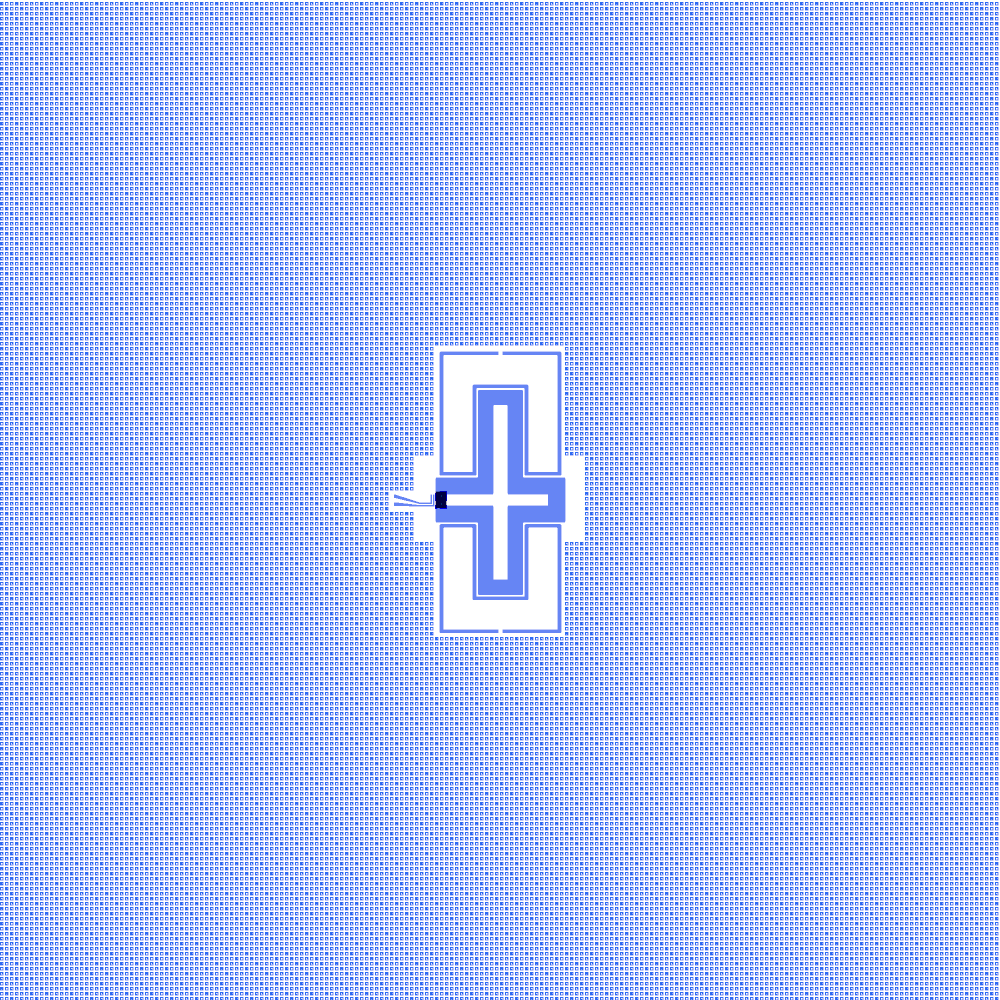

In [7]:
a, b, r = 10, 6, 100
T = dict(lengths=[a / 2 + b + 50, a / 2 + b + 50, a / 2 + b + 2 * a], port_names=["right", "left", "bottom"])
t_len, t_stub = 2 * T["lengths"][0], T["lengths"][2]       # KQC cross1_length (right ↔ left), base → bottom


def cap_params(fingers, length, kind):                     # KQC util.coupler_lib.cap_params
    p = dict(finger_number=fingers, finger_length=length, finger_gap_end=5, finger_gap=5, finger_width=15,
             ground_padding=10)
    if kind == "gap":
        p |= dict(finger_length=0, finger_gap_end=length, finger_gap=0, finger_width=10)
    return p


def meander_path(start, end, length, meanders):  # KQC Meander's centre line in chip coordinates (scratch layout)
    from kqcircuits.elements.meander import Meander
    ly = pya.Layout()
    cell = Meander.create(ly, start_point=list(start), end_point=list(end), length=length, meanders=meanders,
                          r=r, a=a, b=b)
    inst = next(cell.each_inst())                          # its one WaveguideCoplanar
    path = ly.cell(inst.cell_index).pcell_parameters_by_name()["path"]
    return [((inst.dcplx_trans * p).x, (inst.dcplx_trans * p).y)
            for p in (path.each_point() if hasattr(path, "each_point") else path)]


def wg_length(points):                                     # KQC WaveguideCoplanar(path).length()
    from kqcircuits.elements.waveguide_coplanar import WaveguideCoplanar
    ly = pya.Layout()
    return WaveguideCoplanar.create(ly, path=pya.DPath([pya.DPoint(*p) for p in points], 1), r=r, a=a, b=b).length()


with d.batch():
    q = d.add("QB", "Swissmon", at=(4000, 5000), rot=270, arm_width=[30, 23, 30, 23], arm_length=[190, 96, 160, 96],
              gap_width=[29.5, 33, 29.5, 33], island_r=2, cpl_length=[235, 0, 205], cpl_width=[60, 42, 60],
              cpl_gap=[110, 112, 110], cl_offset=[150, 150], junction=JUNCTION, **JJ_PARAMS)
snap(d, STEPS / "3_components.png", box=(3000, 4000, 5000, 6000), size=(1000, 1000), width=420);

## 6 · Routes

**Charge and flux lines.** The charge line from WN ends 6 µm short of the drive port (`term2=b`); the flux line
comes from WS. Both turn one radius in from the launcher.

In [8]:
with d.batch():
    (wnx, _), (wsx, _) = port_xy(d, "chip.WN"), port_xy(d, "chip.WS")
    _, dy = port_xy(d, "QB.drive")
    _, fy = port_xy(d, "QB.flux")
    d.route("CL", "chip.WN", q.drive, nodes=[(wnx + r, dy)], term2=b)        # charge line, open end b = 6 µm
    d.route("FL", "chip.WS", q.flux, nodes=[(wsx + r, fy)])                  # flux line

**The two chains**, built in order because each element is placed on a port of the previous one, as in KQC. Per
chain (A up from coupler 0, B mirrored down from coupler 2):

1. the readout λ/4: a straight from the coupler to T a (KQC's length formula), the KQC meander T a → T b, and the
   shorted stub from T b's bottom arm (`d.free_end(..., term=0)`);
2. the J gap capacitor snapped to T b, T c snapped to it, the Purcell λ/4: the KQC meander from T c with the 400 µm
   leg down to the κ interdigital capacitor, and the shorted stub from T c;
3. the output from the κ capacitor to EN / ES, and the drive gap capacitor on T a with its line to NW / SW.

`wg2_len` is the 400 µm leg's length, which KQC computes once (on chain A) and reuses for chain B.

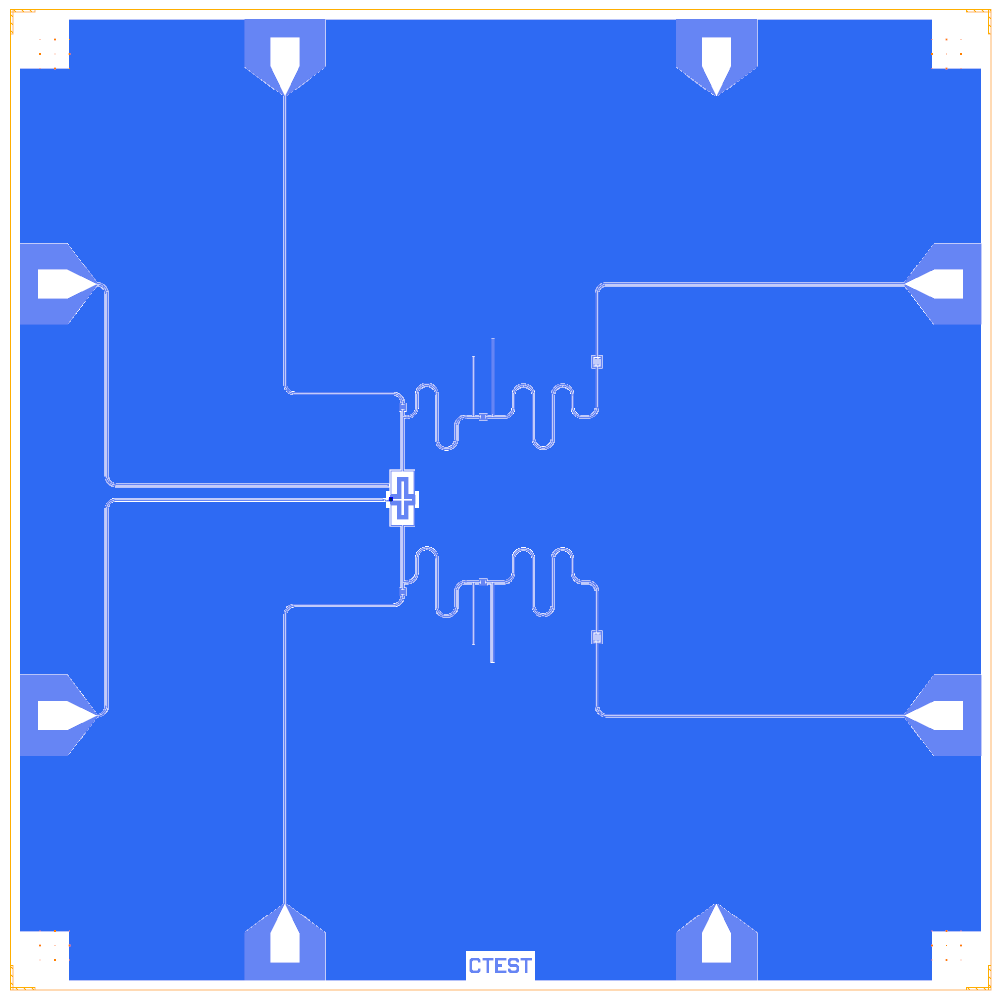

{'CL': 4934.16, 'FL': 5021.83, 'RA1': 489.59, 'RA2': 1681.76, 'RA3': 580.59, 'PA1': 3036.32, 'PA2': 758.58, 'OA': 3825.09, 'DA': 4250.37, 'RB1': 512.71, 'RB2': 1751.13, 'RB3': 603.71, 'PB1': 3131.65, 'PB2': 782.41, 'OB': 3829.07, 'DB': 4257.25}


In [9]:
KQC_R = {"r": r}                                           # drawn turn radius of the meander routes (see above)
chains = (  # chain, qubit coupler, direction, readout targets, Purcell targets, caps (J, κ, drive), output, drive pad
    ("A", "cplr0", +1, [611.586, 1834.76, 611.586], [3158.32, 789.581], [37.5, 67.9, 36.2], "EN", "NW"),
    ("B", "cplr2", -1, [634.71, 1904.13, 634.71], [3253.65, 813.413], [36.8, 71.5, 36.2], "ES", "SW"),
)
wg2_len = None                                             # KQC reuses the readout chain's Purcell leg length
for ch, cplr, s, rr, pr, caps, out, pad in chains:
    up = s > 0
    L, R = ("left", "right") if up else ("right", "left")   # KQC: the readout chain uses left/right, the mirrored one right/left
    with d.batch():
        # readout λ/4: straight from the coupler → T a → meander (2) → T b → shorted stub
        cx, cy = port_xy(d, f"QB.{cplr}")
        ta = add_aligned(d, f"T{ch}a", "WaveguideCoplanarSplitter", L, (cx, cy + s * (rr[0] - t_len)), rot=90, **T)
        d.route(f"R{ch}1", f"QB.{cplr}", ta[L])
        bx, by = port_xy(d, f"T{ch}a.bottom")
        tb = add_aligned(d, f"T{ch}b", "WaveguideCoplanarSplitter", R, (bx + 630, by), rot=180 if up else 0, **T)
        path = meander_path((bx, by), (bx + 630, by), rr[1] - t_len - t_stub, 2)
        d.route(f"R{ch}2", ta.bottom, tb[R], r=10, nodes=path[1:-1]).set(params=KQC_R)
        sx, sy = port_xy(d, f"T{ch}b.bottom")
        d.route(f"R{ch}3", tb.bottom, Designer.free_end((sx, sy + s * (rr[2] - t_stub)), term=0))
        # J capacitor → T c; Purcell λ/4: T c → meander (3) → 400 µm leg → κ capacitor; T c → shorted stub
        cj = d.add(f"C{ch}j", "FingerCapacitorSquare", snap="a", to=tb[L], **cap_params(4, caps[0], "gap"))
        tc = d.add(f"T{ch}c", "WaveguideCoplanarSplitter", snap=R, to=cj.b, **T)
        lx, ly = port_xy(d, f"T{ch}c.{L}")
        m3_end = (lx + 900, ly)
        leg = [m3_end, (m3_end[0] + r, ly), (m3_end[0] + r, ly + s * 400), (m3_end[0] + r, ly + s * (400 + r))]
        wg2_len = wg2_len or wg_length(leg)
        ck = add_aligned(d, f"C{ch}k", "FingerCapacitorSquare", "a", leg[-1], rot=90 if up else 270,
                         **cap_params(4, caps[1], "interdigital"))
        path = meander_path((lx, ly), m3_end, pr[0] - t_len - wg2_len, 3)
        d.route(f"P{ch}1", tc[L], ck.a, r=10, nodes=path[1:] + leg[1:-1]).set(params=KQC_R)
        px, py = port_xy(d, f"T{ch}c.bottom")
        d.route(f"P{ch}2", tc.bottom, Designer.free_end((px, py + s * (pr[1] - t_stub)), term=0))
        # output: κ capacitor → EN / ES; drive: gap capacitor on T a → NW / SW
        kx, _ = port_xy(d, f"C{ch}k.b")
        _, oy = port_xy(d, f"chip.{out}")
        d.route(f"O{ch}", ck.b, f"chip.{out}", nodes=[(kx, oy)])
        cd = d.add(f"C{ch}d", "FingerCapacitorSquare", snap="a", to=ta[R], **cap_params(4, caps[2], "gap"))
        _, iy = port_xy(d, f"C{ch}d.b")
        nx, _ = port_xy(d, f"chip.{pad}")
        d.route(f"D{ch}", cd.b, f"chip.{pad}", nodes=[(nx, iy + s * r)])
snap(d, STEPS / "4_routes.png", box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)
print({k: round(v, 2) for k, v in d.result.route_lengths().items()})

**Sim groups, centring, save.** A Q3D C-matrix of the qubit alone (island, coupler pads, charge and flux lines;
150 µm margin, clear of the meanders) and per chain an eigenmode job with the qubit, both resonators and the
capacitors (100 µm margin). `center_in_die` checks that the content sits centred in the die and shifts it if it is
more than 50 µm off. Then `shaping.json` is saved.

In [10]:
d.sim_group("QB", ["QB"], margin_um=150, analyses=["q3d_cmatrix"])   # 150 µm: clear of the meanders
for ch in "AB":
    d.sim_group(f"QB_{ch}", ["QB"] + [f"{p}{ch}{x}" for p, x in (("T", "a"), ("T", "b"), ("T", "c"), ("C", "j"),
                ("C", "k"), ("C", "d"), ("R", 1), ("R", 2), ("R", 3), ("P", 1), ("P", 2))],
                margin_um=100, analyses=["eigenmode_epr"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN = d.save(OUT / "shaping.json")
print(d, "→", DESIGN)

centring shift (µm): (0.0, 0.0)


<Designer shaping: 13 instances, 16 routes, live=False> → examples\designs\kqc\test_chips\shaping.json


## 7 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Here:** DRC clean, with one `dangling_port` warning: the Swissmon's zero-length coupler 1 (`cpl_length = [235, 0, 205]`; the LOM puts its port on ground). No PDK design warning (device R_n 45 kΩ, f_q ≈ 6.5 GHz). `pdk_report` gives KQC's grid as the cheese ("the original design's own"), the content centred (0, 0) and "Quantcore Squid × 1".

In [11]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 1 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 1 | QB.cplr1 is not connected (no route or snap) |

| check | value |
|---|---|
| cheese | the original design's own (or none) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Squid × 1 |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit. The qubit island (C and the SQUID to ground) has its coupler
nodes 0 and 2. Each coupler node carries its chain's readout λ/4 (`R*3`, one `TLres` of the chain's summed routes)
and the drive and J capacitors; the J capacitor's far node carries the Purcell λ/4 (`P*2`) and the κ capacitor
into the output launcher (50 Ω). The charge line is a drive control, the flux line a flux control.

In [12]:
lb = d.lom()
show_netlist(lb)

**11 nodes · 34 branches · 2 controls · 1 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `QB` | `QB.island` |
| `QB.cplr0` | `QB.cplr0`, `TAa.t`, `TAb.t`, `CAj.a`, `CAd.a` |
| `QB.cplr2` | `QB.cplr2`, `TBa.t`, `TBb.t`, `CBj.a`, `CBd.a` |
| `CAj.b` | `CAj.b`, `TAc.t`, `CAk.a` |
| `CAk.b` | `CAk.b`, `chip.EN` |
| `CAd.b` | `CAd.b`, `chip.NW` |
| `CBj.b` | `CBj.b`, `TBc.t`, `CBk.a` |
| `CBk.b` | `CBk.b`, `chip.ES` |
| `CBd.b` | `CBd.b`, `chip.SW` |
| `chip.WN` | `chip.WN` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `C_QB` | C | `QB` – `gnd` | 54.8 fF |
| `J_QB` | SQUID | `QB` – `gnd` | Lj 6.73 nH, Cj 15 fF |
| `Cg_QB_cplr0` | C | `QB` – `QB.cplr0` | 7.4 fF |
| `Cc_QB_cplr0` | C | `QB.cplr0` – `gnd` | 153 fF |
| `Cg_QB_cplr2` | C | `QB` – `QB.cplr2` | 6.5 fF |
| `Cc_QB_cplr2` | C | `QB.cplr2` – `gnd` | 139 fF |
| `C_CAj` | C | `QB.cplr0` – `CAj.b` | 2.13 fF |
| `C_CAj_a` | C | `QB.cplr0` – `gnd` | 6.2 fF |
| `C_CAj_b` | C | `CAj.b` – `gnd` | 6.2 fF |
| `C_CAk` | C | `CAj.b` – `CAk.b` | 21.8 fF |
| `C_CAk_a` | C | `CAj.b` – `gnd` | 13 fF |
| `C_CAk_b` | C | `CAk.b` – `gnd` | 13 fF |
| `C_CAd` | C | `QB.cplr0` – `CAd.b` | 2.15 fF |
| `C_CAd_a` | C | `QB.cplr0` – `gnd` | 6.1 fF |
| `C_CAd_b` | C | `CAd.b` – `gnd` | 6.1 fF |
| `C_CBj` | C | `QB.cplr2` – `CBj.b` | 2.14 fF |
| `C_CBj_a` | C | `QB.cplr2` – `gnd` | 6.1 fF |
| `C_CBj_b` | C | `CBj.b` – `gnd` | 6.1 fF |
| `C_CBk` | C | `CBj.b` – `CBk.b` | 22.7 fF |
| `C_CBk_a` | C | `CBj.b` – `gnd` | 14 fF |
| `C_CBk_b` | C | `CBk.b` – `gnd` | 14 fF |
| `C_CBd` | C | `QB.cplr2` – `CBd.b` | 2.15 fF |
| `C_CBd_a` | C | `QB.cplr2` – `gnd` | 6.1 fF |
| `C_CBd_b` | C | `CBd.b` – `gnd` | 6.1 fF |
| `Port_WN` | R | `chip.WN` – `gnd` | 50 Ω |
| `Port_EN` | R | `CAk.b` – `gnd` | 50 Ω |
| `Port_NW` | R | `CAd.b` – `gnd` | 50 Ω |
| `Port_ES` | R | `CBk.b` – `gnd` | 50 Ω |
| `Port_SW` | R | `CBd.b` – `gnd` | 50 Ω |
| `Cd_QB` | C | `QB` – `chip.WN` | 0.1 fF |
| `RA3` | TLres | `QB.cplr0` – `gnd` | lambda/4, 2752 µm, 11.450 GHz |
| `PA2` | TLres | `CAj.b` – `gnd` | lambda/4, 3795 µm, 8.303 GHz |
| `RB3` | TLres | `QB.cplr2` – `gnd` | lambda/4, 2868 µm, 10.988 GHz |
| `PB2` | TLres | `CBj.b` – `gnd` | lambda/4, 3914 µm, 8.050 GHz |

| control | kind | target | line | length (µm) |
|---|---|---|---|---|
| `CL` | drive | `J_QB` | `CL` | 4934 |
| `FL` | flux_bias | `J_QB` | `FL` | 5022 |

**Unconnected ports:** `QB.cplr1`

**Builder notes:**

- QB.cplr1: cpl_length 0 (no coupler), its port ends on ground
- RA3: one lambda/4 line of 2752 µm = route + ['RA1', 'RA2'] (the wires join it to its coupler end; any other branch on that conductor is a tap, not modelled as a separate line)
- PA2: one lambda/4 line of 3795 µm = route + ['PA1'] (the wires join it to its coupler end; any other branch on that conductor is a tap, not modelled as a separate line)
- RB3: one lambda/4 line of 2868 µm = route + ['RB1', 'RB2'] (the wires join it to its coupler end; any other branch on that conductor is a tap, not modelled as a separate line)
- PB2: one lambda/4 line of 3914 µm = route + ['PB1'] (the wires join it to its coupler end; any other branch on that conductor is a tap, not modelled as a separate line)
- Port_WS: both ends on gnd after merging conductors (dropped)

## 9 · LOM simulation

The whole circuit: QuCat's normal modes, the QuTiP-dressed qubit values and, per qubit, its most strongly coupled
resonator. Rough, see the LOM approximation above (taps at the open end, T arms not counted). The last table
compares each λ/4's LOM line with KQC's segment targets.

In [13]:
res = simulate_lom(lb, d.design, max_modes=3)
display(Markdown(modes_md(res)))
display(Markdown(summary_md(res)))
display(Markdown(pairs_md(res)))

# λ/4 lengths: LOM (sum of the chain's routes) vs KQC's segment targets (which include the T arms)
lengths = d.result.route_lengths()
rows = ["| resonator | LOM line (µm) | KQC target sum (µm) | T arms not in the LOM (µm) |", "|---|---|---|---|"]
for ch, _, _, rr, pr, *_ in chains:
    for name, routes, target in ((f"R{ch}3", ("1", "2", "3"), sum(rr)), (f"P{ch}2", ("1", "2"), sum(pr))):
        lom = sum(lengths[f"{name[0]}{ch}{k}"] for k in routes)
        rows.append(f"| {name} | {lom:.1f} | {target:.1f} | {target - lom:.1f} |")
display(Markdown("\n".join(rows)))

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| QB | qubit | 6.6802 | 0.0036 | 222.4 | J_QB 0.98 |
| PB2 | resonator | 7.4763 | 27.5 | 0.0 | PB2 1.00 |
| PA2 | resonator | 7.7162 | 27.9 | 0.0 | PA2 1.00 |
| RB3 | resonator | 8.2385 | 0.308 | 0.0 | RB3 0.96, RA3 0.03 |
| RA3 | resonator | 8.3451 | 0.326 | 0.0 | RA3 0.96, RB3 0.03, J_QB 0.01 |

| parameter | LOM (QuTiP) | target |
|---|---|---|
| `QB.f_q_GHz` | 6.4498 | – |
| `QB.alpha_MHz` | -241.76 | – |
| `PB2.chi_MHz` | -0.0056918 | – |
| `PA2.chi_MHz` | -0.0084654 | – |
| `PB2.f_GHz` | 7.4763 | – |
| `PB2.kappa_MHz` | 27.484 | – |
| `PA2.f_GHz` | 7.7162 | – |
| `PA2.kappa_MHz` | 27.879 | – |

| qubit | f_q (GHz) | A (MHz) | resonator | f_r (GHz) | κ_r (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|
| QB | 6.6802 | 222.4 | RA3 | 8.3451 | 0.326 | -6.46 |

| resonator | LOM line (µm) | KQC target sum (µm) | T arms not in the LOM (µm) |
|---|---|---|---|
| RA3 | 2751.9 | 3057.9 | 306.0 |
| PA2 | 3794.9 | 3947.9 | 153.0 |
| RB3 | 2867.6 | 3173.6 | 306.0 |
| PB2 | 3914.1 | 4067.1 | 153.0 |

**Here:** five modes: the qubit at 6.680 GHz (QuCat; QuTiP-dressed 6.450 GHz, α −242 MHz; KQC's assumed 12 nH gave ≈ 5.2 GHz); the two Purcell filters at 7.476 (PB2) and 7.716 GHz (PA2), κ ≈ 28 MHz into their outputs; the two readouts at 8.239 (RB3) and 8.345 GHz (RA3), κ 0.31 / 0.33 MHz through their filters; χ of the qubit with RA3 ≈ −6.5 MHz. Each readout λ/4 is 306 µm and each filter 153 µm shorter in the LOM than KQC's targets (the T arms, last table), so these LOM frequencies sit high.

## 10 · FEM: send the jobs

One job per sim group and analysis: the group is cut out of the chip with its margin, every line leaving the
box ends in a port, junctions are lumped ports, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and C-matrix nets (named after islands, couplers and routes, so the
result maps back onto the LOM nodes).

With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, `send_fem_jobs` solves each Ansys job in a **new
batch, non-graphical** AEDT (`solve_job`) — an AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

Here: a Q3D C-matrix of the qubit, and per chain an eigenmode job with the qubit (its junction a lumped
port), both resonators and the capacitors: the lines leaving the box (output, drive, the other chain's
straight, charge and flux lines) end in 50 Ω, so the solve gives the readout and Purcell modes, their χ
and the Purcell-filtered κ.

In [14]:
jobs = send_fem_jobs(DESIGN, run=RUN_FEM)
display(Markdown(jobs_md(jobs) if jobs else "No sim groups: no FEM job."))

3 job(s) exported; RUN_FEM is False, nothing solved.


| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| QB · q3d_cmatrix | `build/jobs/shaping_QB_q3d_cmatrix` | 1 · junction · `QB.junction`<br>2 · edge · `CL`<br>3 · edge · `FL`<br>4 · edge · `RA1`<br>5 · edge · `RB1` | `QB.island`, `CL`, `RA1`, `RB1` |
| QB_A · eigenmode_epr | `build/jobs/shaping_QB_A_eigenmode_epr` | 1 · junction · `QB.junction`<br>2 · edge_lumped · `CL`<br>3 · edge_lumped · `DA`<br>4 · edge_lumped · `FL`<br>5 · edge_lumped · `OA`<br>6 · edge_lumped · `RB1` | `QB.island`, `CL`, `DA`, `FL`, `OA`, `RB1` |
| QB_B · eigenmode_epr | `build/jobs/shaping_QB_B_eigenmode_epr` | 1 · junction · `QB.junction`<br>2 · edge_lumped · `CL`<br>3 · edge_lumped · `DB`<br>4 · edge_lumped · `FL`<br>5 · edge_lumped · `OB`<br>6 · edge_lumped · `RA1` | `QB.island`, `CL`, `DB`, `FL`, `OB`, `RA1` |

## 11 · Bring the results back

When a job has been solved its folder holds `results/results.json`. `fem_back` then calls
`fill(model, design, job)`: the C-matrix (or eigenmode) values replace the component estimates branch by
branch (matched by net name), and the table compares the two. `simulate(filled)` re-runs the LOM on the
extracted values. Until then the cell says which jobs are still waiting.

In [15]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md or "No FEM jobs."))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM results yet for QB · q3d_cmatrix, QB_A · eigenmode_epr, QB_B · eigenmode_epr: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Change one property and re-simulate

The Purcell filter's κ capacitor sets how fast the filter (and through it the readout) leaks into the output line.
Lengthen chain A's κ fingers from 67.9 to 90 µm: the filter's κ rises and, through the J capacitor, the readout's
too; the frequencies barely move. The change is made on a copy (`design_copy`), so `shaping.json` keeps KQC's
67.9 µm.

In [16]:
d2 = design_copy(DESIGN)
d2["CAk"].set(finger_length=90)
res2 = simulate_lom(d2.lom(), d2.design, max_modes=3)
m0, m1 = {m.label: m for m in res.modes}, {m.label: m for m in res2.modes}
display(Markdown("**CAk fingers: 67.9 → 90 µm**\n\n| mode | kind | f before (GHz) | f after (GHz) | κ before (MHz) | κ after (MHz) |\n"
                 "|---|---|---|---|---|---|\n" + "\n".join(
                     f"| {k} | {m0[k].kind} | {m0[k].f_GHz:.4f} | {m1[k].f_GHz:.4f} | {m0[k].kappa_MHz:.3g} | {m1[k].kappa_MHz:.3g} |"
                     for k in m0 if k in m1)))

**CAk fingers: 67.9 → 90 µm**

| mode | kind | f before (GHz) | f after (GHz) | κ before (MHz) | κ after (MHz) |
|---|---|---|---|---|---|
| QB | qubit | 6.6802 | 6.6802 | 0.0036 | 0.00363 |
| PB2 | resonator | 7.4763 | 7.4763 | 27.5 | 27.5 |
| PA2 | resonator | 7.7162 | 7.6490 | 27.9 | 41.7 |
| RB3 | resonator | 8.2385 | 8.2385 | 0.308 | 0.309 |
| RA3 | resonator | 8.3451 | 8.3450 | 0.326 | 0.339 |

**Result.** the filter PA2 moves from 7.716 to 7.649 GHz (−67 MHz) and its κ from 27.9 to 41.7 MHz; the readout RA3's κ rises from 0.326 to 0.339 MHz (through the J capacitor); the qubit and chain B do not move.

## 13 · Build and export

**The design file.** `shaping.json` (saved in step 6) is the whole design: `qcc build
examples/designs/kqc/test_chips/shaping.json` rebuilds `build/shaping.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese
hole), the trilayer fingers 2/0 + 4/0 and spacer 50–53/0,
and the frame (100/0, 1000/0, 1001/0). The cheese source is `build`: KQC's grid drawn in the build (`with_grid=True`) stands, and no PDK
band is added. In this run: 1/0 888 428 polygons, 3/0 868 989 (the keep-outs merge with neighbouring grid holes), 888 419 grid holes; the export takes ≈ 20 s here. Corner rounding (fab only) is skipped unless `FULL_FAB`;
`qcc mask examples/designs/kqc/test_chips/shaping.json` writes the complete file.

In [17]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 888428 |
| 2/0 | JJ_STRAIGHT | 1 |
| 3/0 | M3 | 868989 |
| 4/0 | JJ_BENT | 1 |
| 50/0 | HSQ | 4 |
| 51/0 | SPACER_1 | 4 |
| 52/0 | SPACER_2 | 4 |
| 53/0 | SPACER_3 | 4 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 888419 holes on the mask.

→ `build/shaping_fab.oas`

**Simulation export options.** A simulation export never has cheese; airbridges are dropped for speed unless
`airbridges=True` (or the sim group's `settings={"airbridges": True}`), and the builder notes which crossing
lines are then open. `setup.geometry` says what the export left out. This chip has no airbridges, so both settings give the same geometry.

In [18]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "QB_A", "eigenmode_epr", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

airbridges=False: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'dropped'} QB: junction L 6.734 nH, C 15 fF (design; Φ = 0, d = 0)


airbridges=True: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'kept'} QB: junction L 6.734 nH, C 15 fF (design; Φ = 0, d = 0)


## 14 · Snapshots

The full chip (KQC's grid fills the ground as one tone at this scale); the readout chain; the qubit; its SQUID and
flux line; the J capacitor between the two T's; the die frame's south-west corner (dicing L on 1000/0, 3 × 3
alignment grid on 1001/0); and the qubit in the **fab view** (the mask from step 13: 1/0 and 3/0 with the grid
holes, the trilayer layers). The chip boundary 100/0 is drawn as an outline.

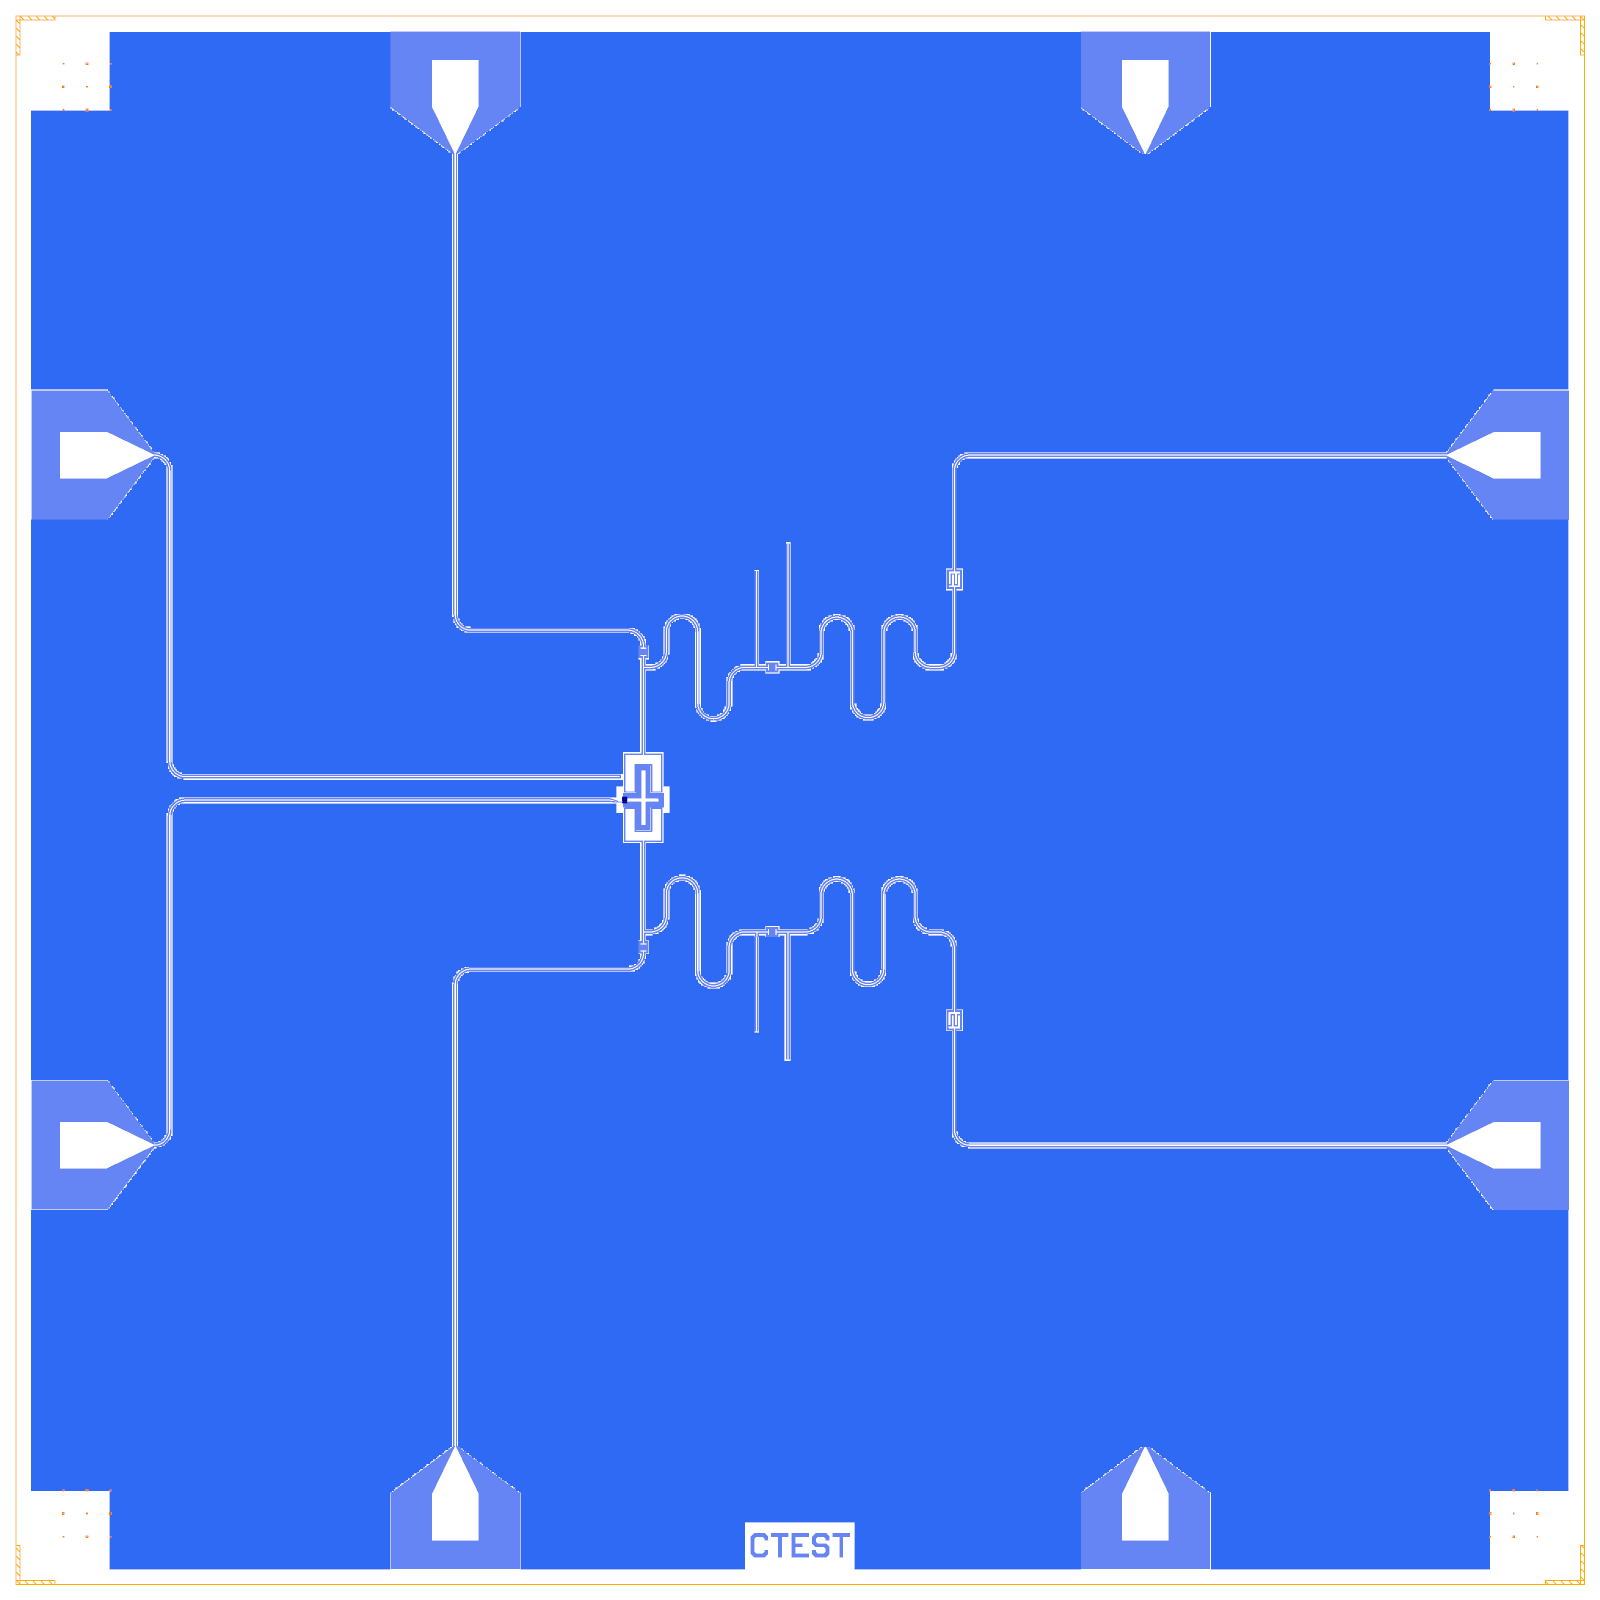

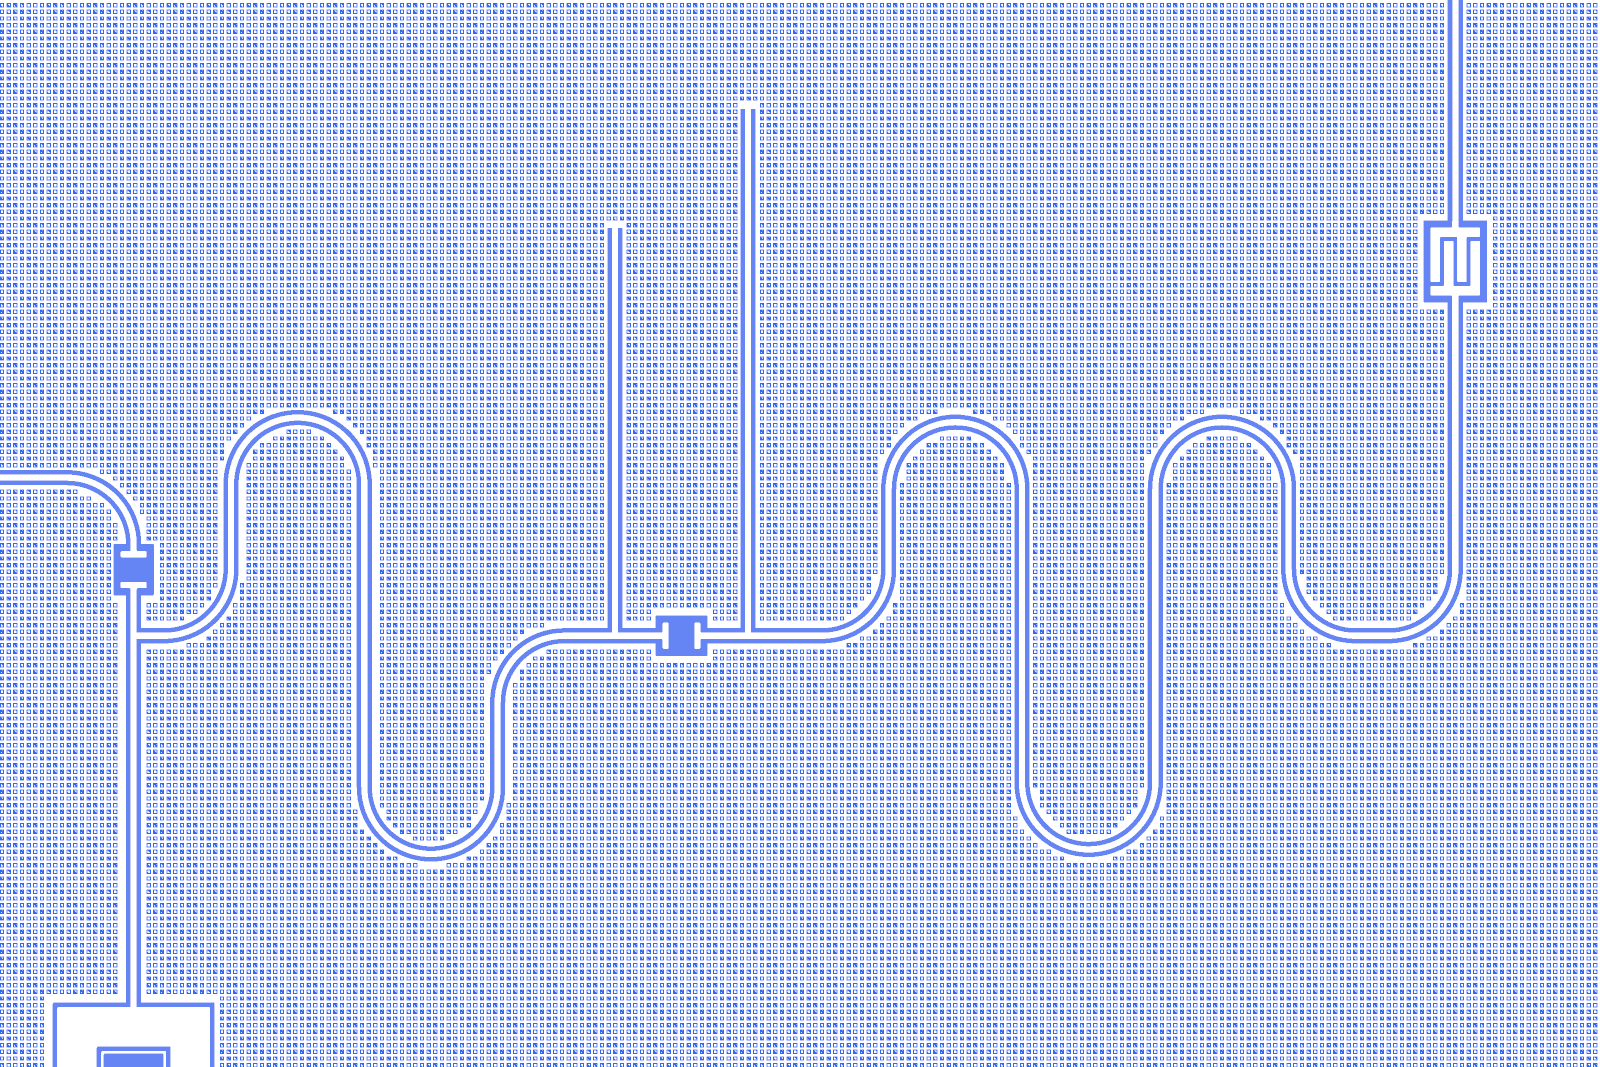

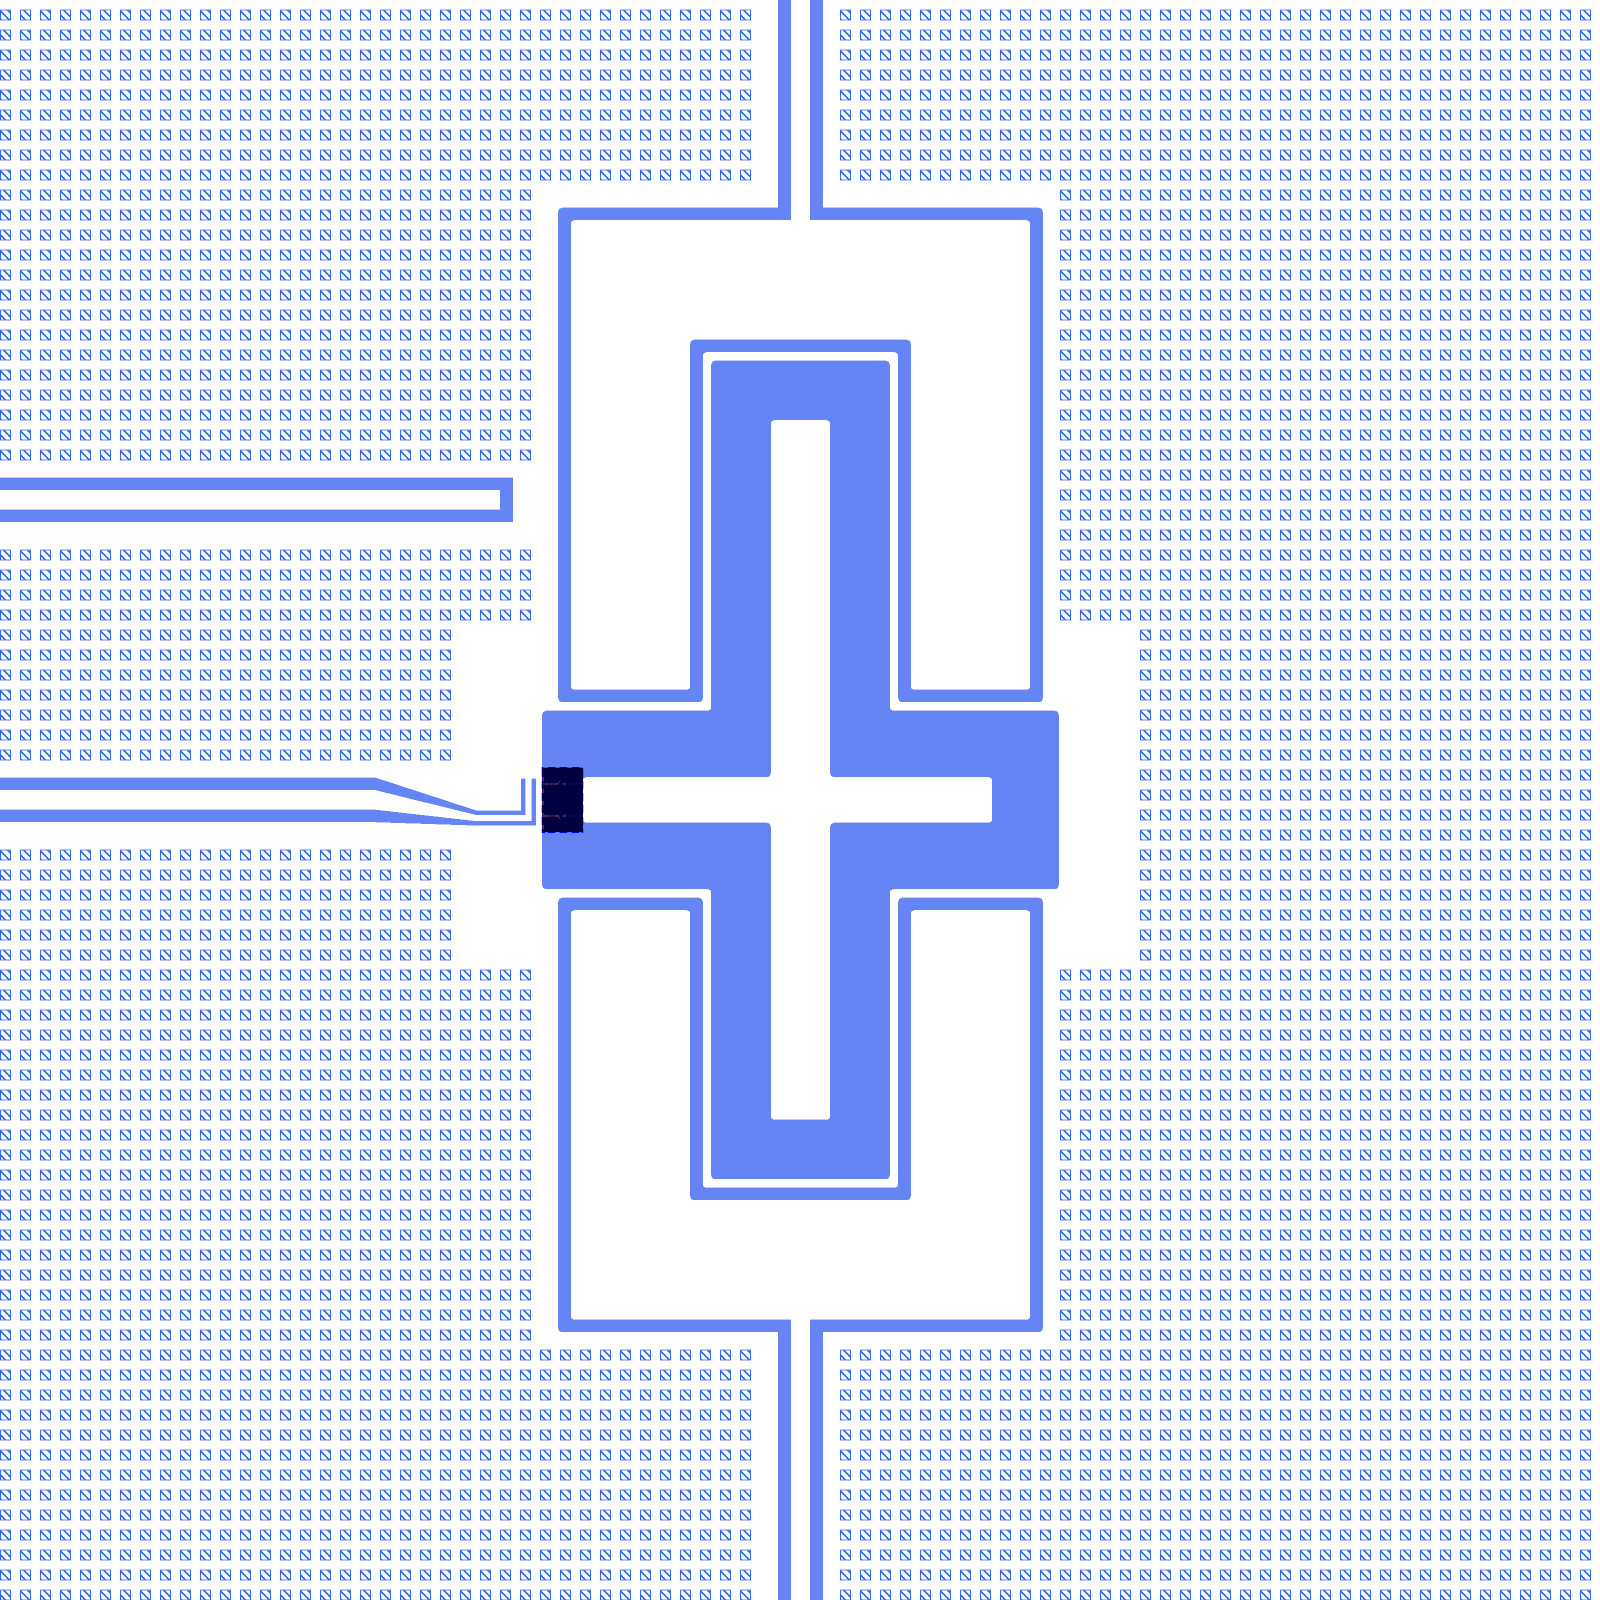

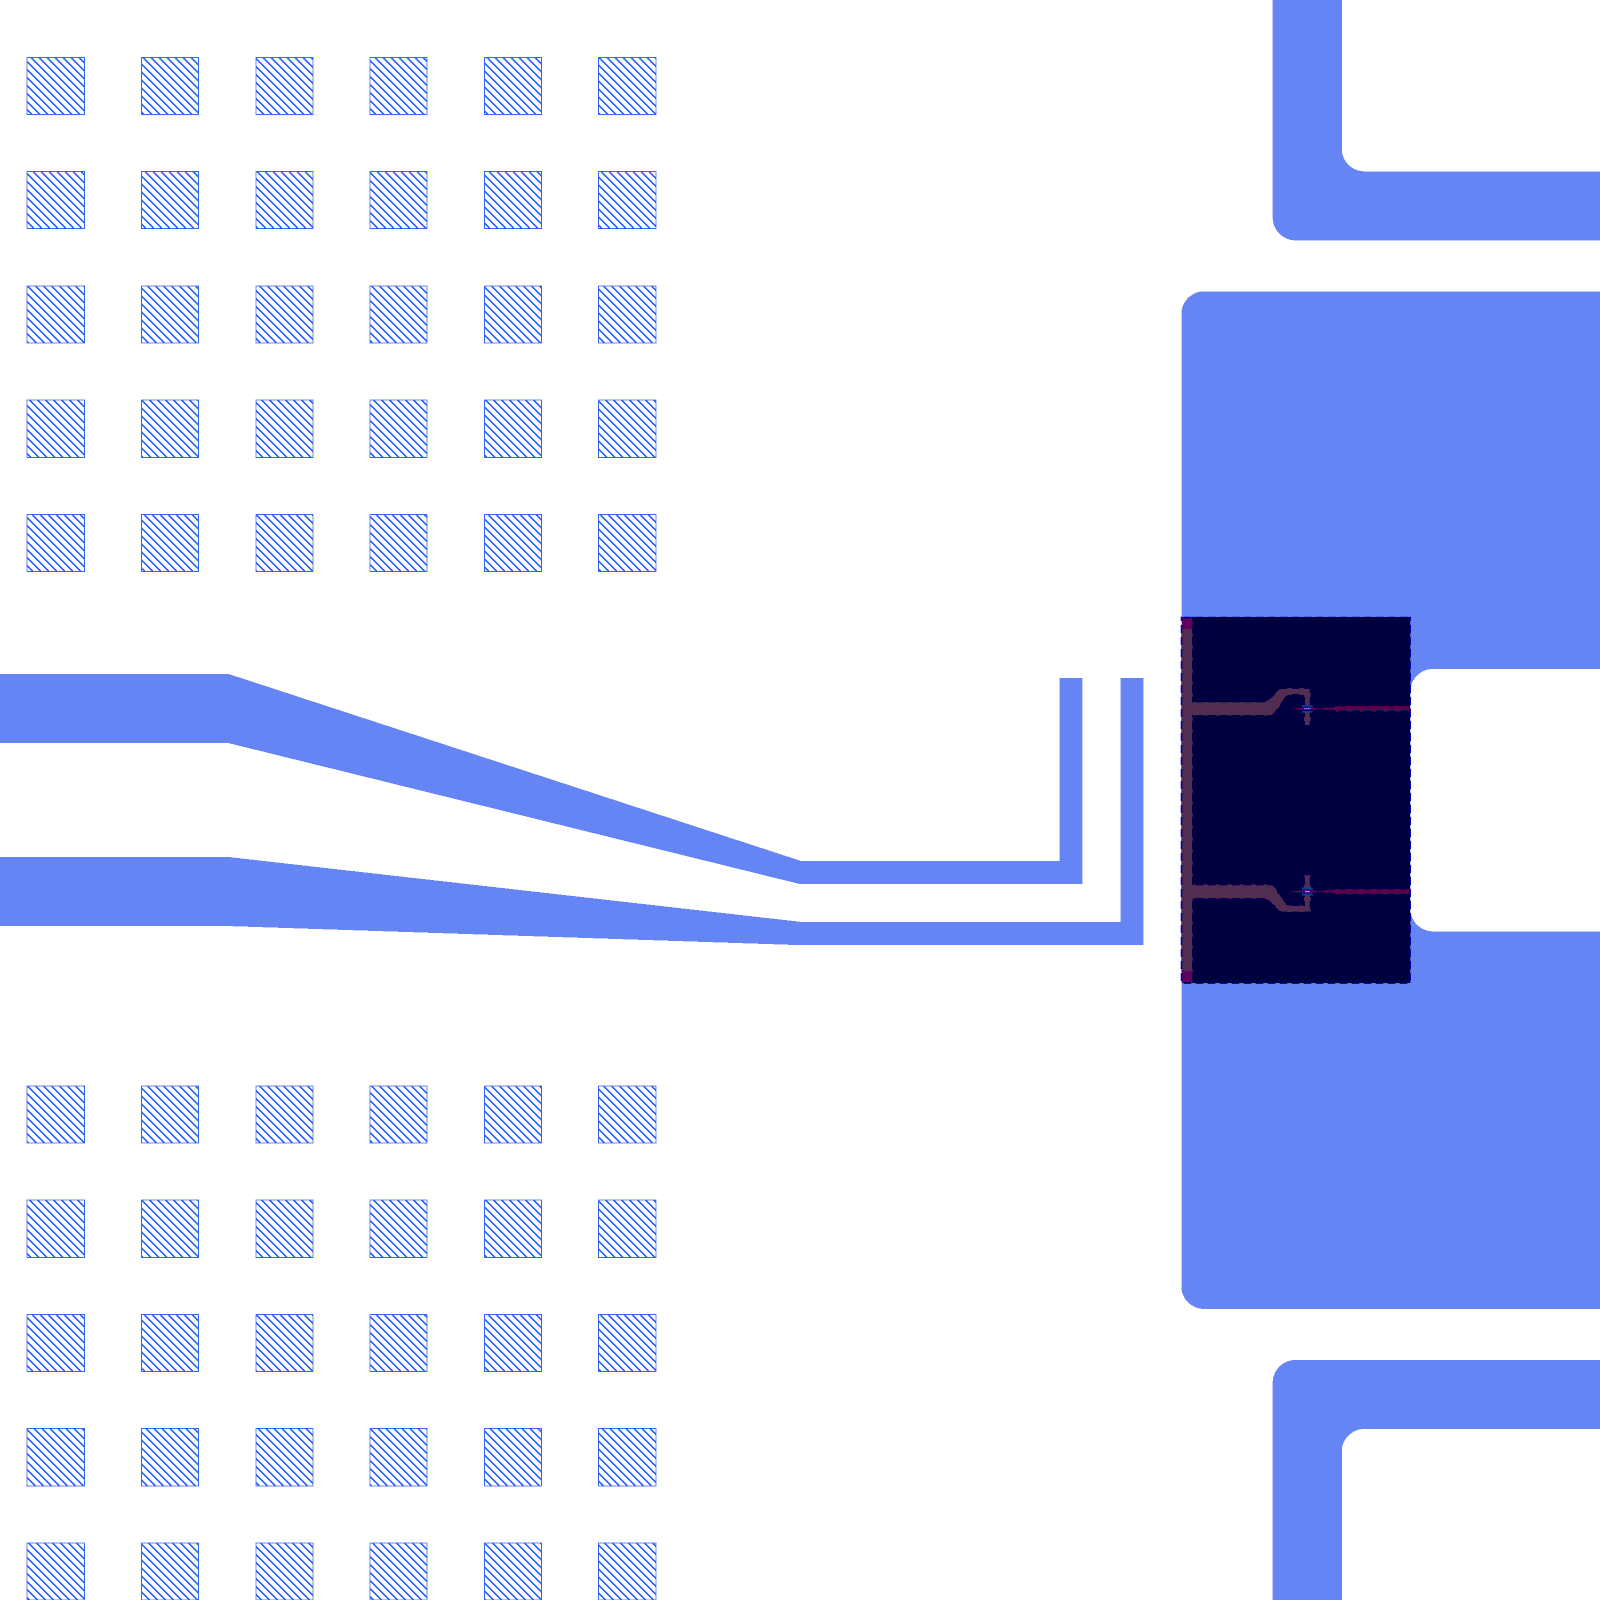

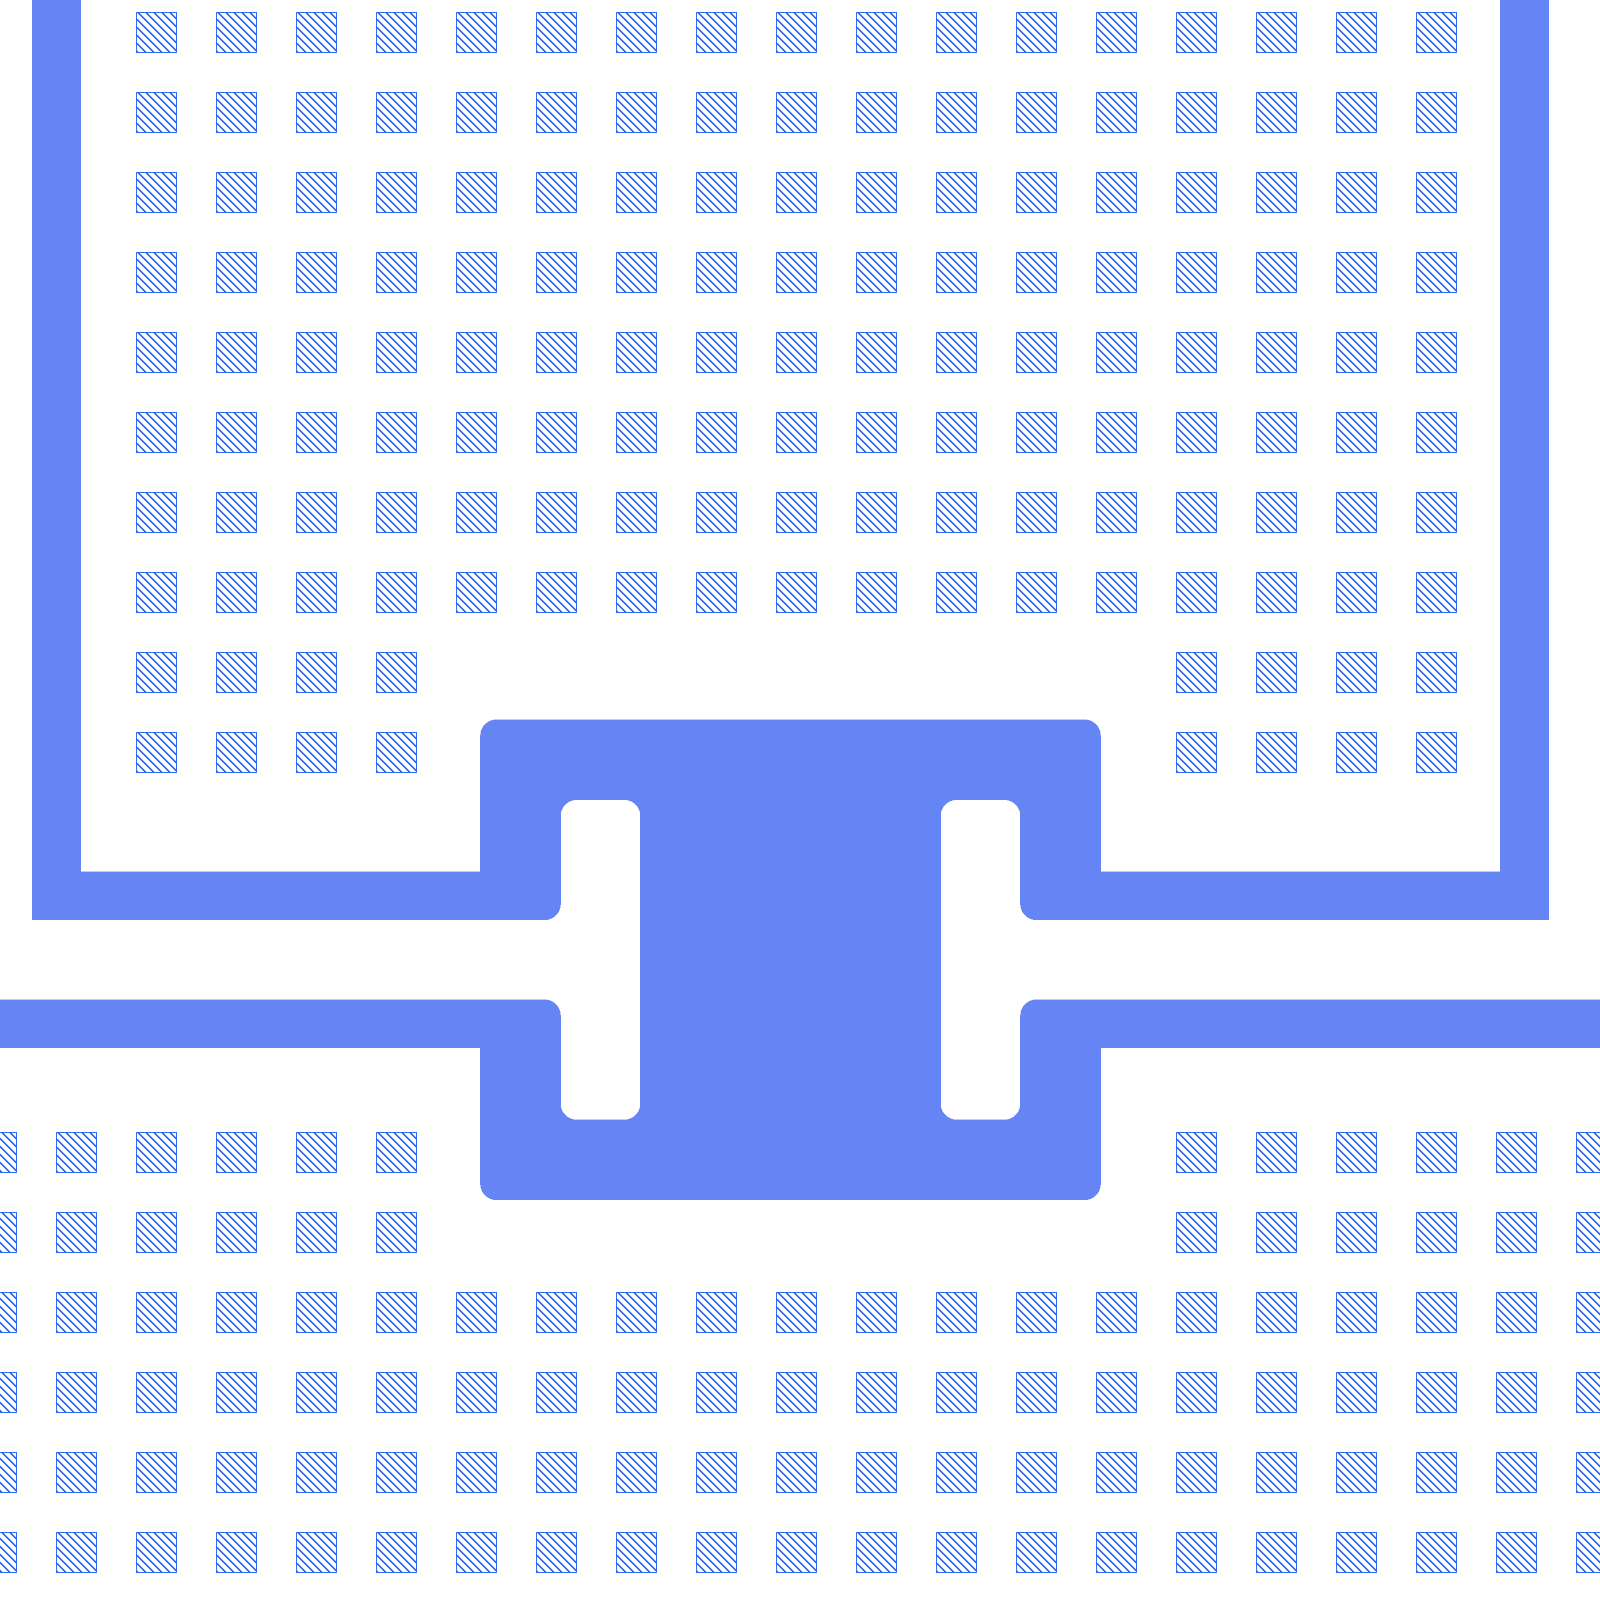

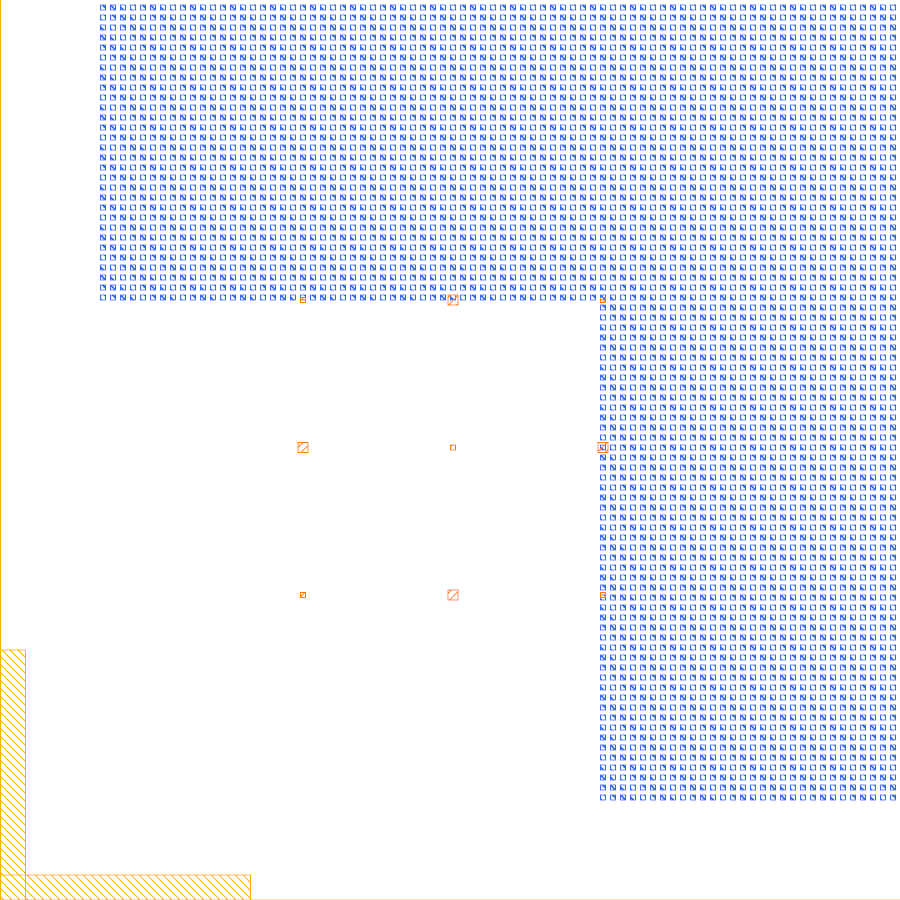

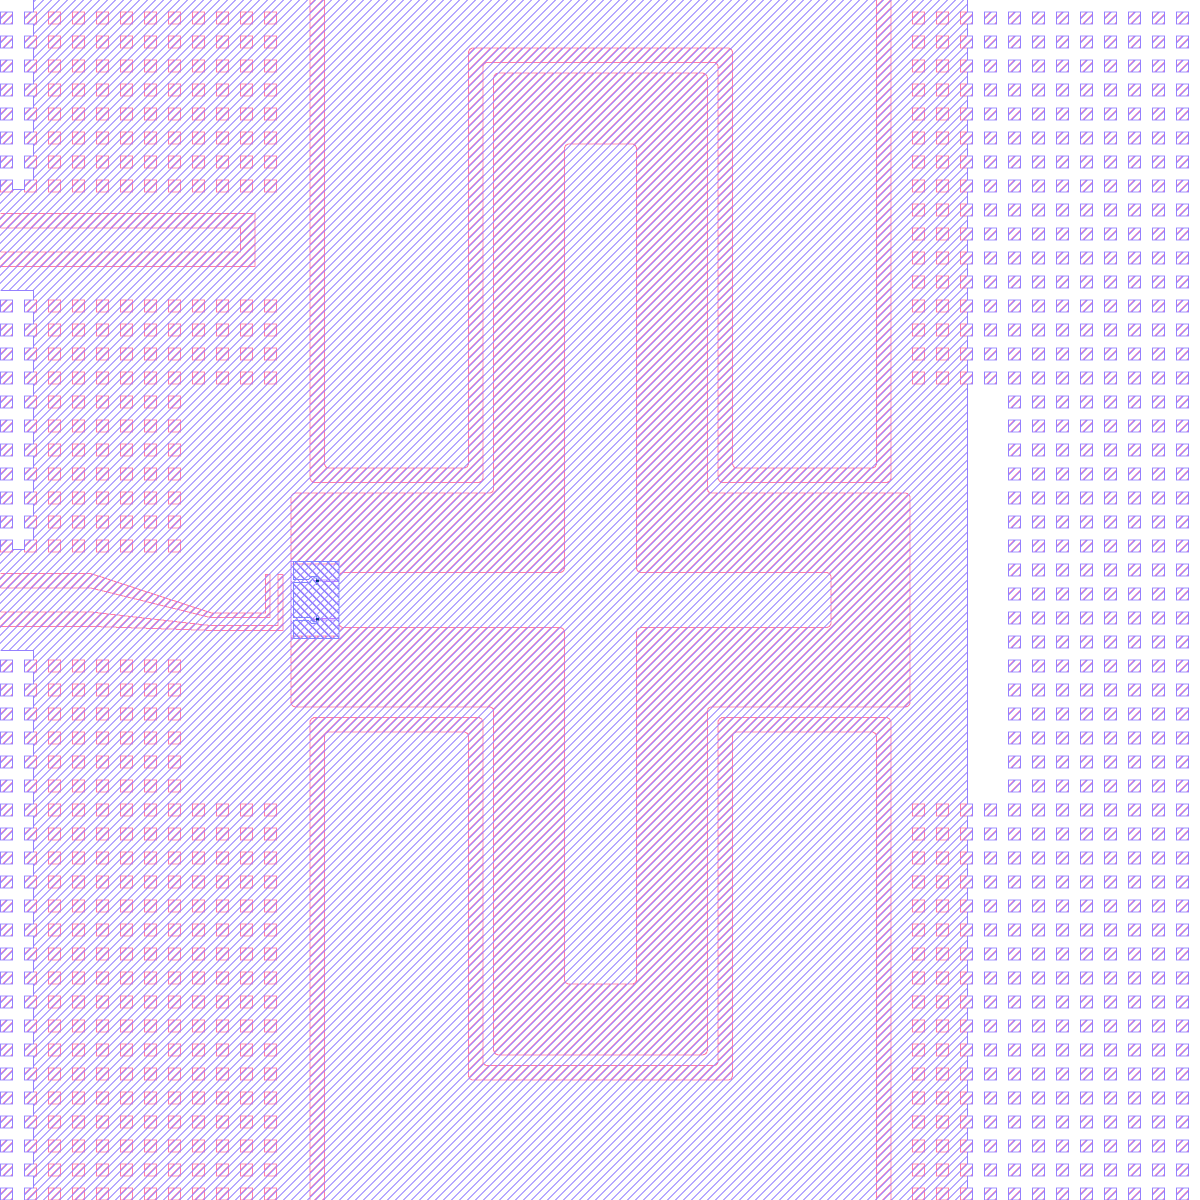

In [19]:
show_snapshot(d, OUT / "shaping.png", box=(-100, -100, 10100, 10100))
show_snapshot(d, OUT / "shaping_readout.png", box=(3800, 5200, 6200, 6800), size=(1600, 1067), width=640)
show_snapshot(d, OUT / "shaping_qb.png", box=(3600, 4600, 4400, 5400), width=420)
fx, fy = port_xy(d, "QB.flux")
show_snapshot(d, OUT / "shaping_squid.png", box=(fx - 20, fy - 70, fx + 120, fy + 70), width=360)
x, y = port_xy(d, "CAj.a")
show_snapshot(d, OUT / "shaping_cap_j.png", box=(x - 60, y - 80, x + 140, y + 120), width=360)
show_snapshot(d, OUT / "shaping_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "shaping_fab.oas", OUT / "shaping_fab_qb.png", box=(3750, 4750, 4250, 5250),
          size=(1200, 1200), width=420);   # fab view: 1/0 + 3/0 with the grid holes, junction layers

**Reference: XOR with the source.** KQC's `Shaping` built stand-alone, XOR-ed layer by layer with this build (the
union of both layer sets; `refpoints`, `ports` and the `instance_names` label layer are annotation and are skipped).
The reference gets `name_brand="QC"`, the brand text a KQC frame would write here. **The rebuild is expected to
differ** by design: the frame (KQC's ChipFrame vs the Quantcore die frame), the junction layers (KQC's Manhattan
SQUID vs the trilayer SQUID), the ground grid (KQC's stand-alone build has none), and the launchers with their
first line legs (80 µm deeper here). The column "> 1 nm" is the XOR shrunk by one database unit: what is left there
is a real difference, not a rounding sliver. A reference, not a pass/fail check.

| layer | XOR area (µm²) | > 1 nm (µm²) |
|---|---|---|
| 1t1_SIS_junction | 470 | 469 |
| 1t1_SIS_junction_2 | 580 | 580 |
| 1t1_SIS_shadow | 406 | 406 |
| 1t1_airbridge_flyover | 2.81e+05 | 2.81e+05 |
| 1t1_airbridge_pads | 5.4e+05 | 5.4e+05 |
| 1t1_base_metal_addition | 686 | 686 |
| 1t1_base_metal_gap_for_EBL | 8.6e+06 | 8.6e+06 |
| 1t1_base_metal_gap_wo_grid | 8.9e+06 | 8.9e+06 |
| 1t1_chip_dicing | 2.68e+05 | 2.68e+05 |
| 1t1_ground_grid | 2.22e+07 | 2.22e+07 |
| 1t1_ground_grid_avoidance | 1.34e+07 | 1.34e+07 |
| 1t1_waveguide_path | 9.32e+04 | 9.31e+04 |
| qcc_chip_boundary | 1e+08 | 1e+08 |
| qcc_marker_0 | 4.75e+04 | 4.75e+04 |
| qcc_marker_1 | 2.1e+03 | 2.1e+03 |
| qcc_spacer | 0.64 | 0.632 |
| qcc_spacer_1 | 0.214 | 0.207 |
| qcc_spacer_2 | 0.211 | 0.204 |
| qcc_spacer_3 | 0.214 | 0.207 |

**Total XOR area: 1.54e+08 µm²**

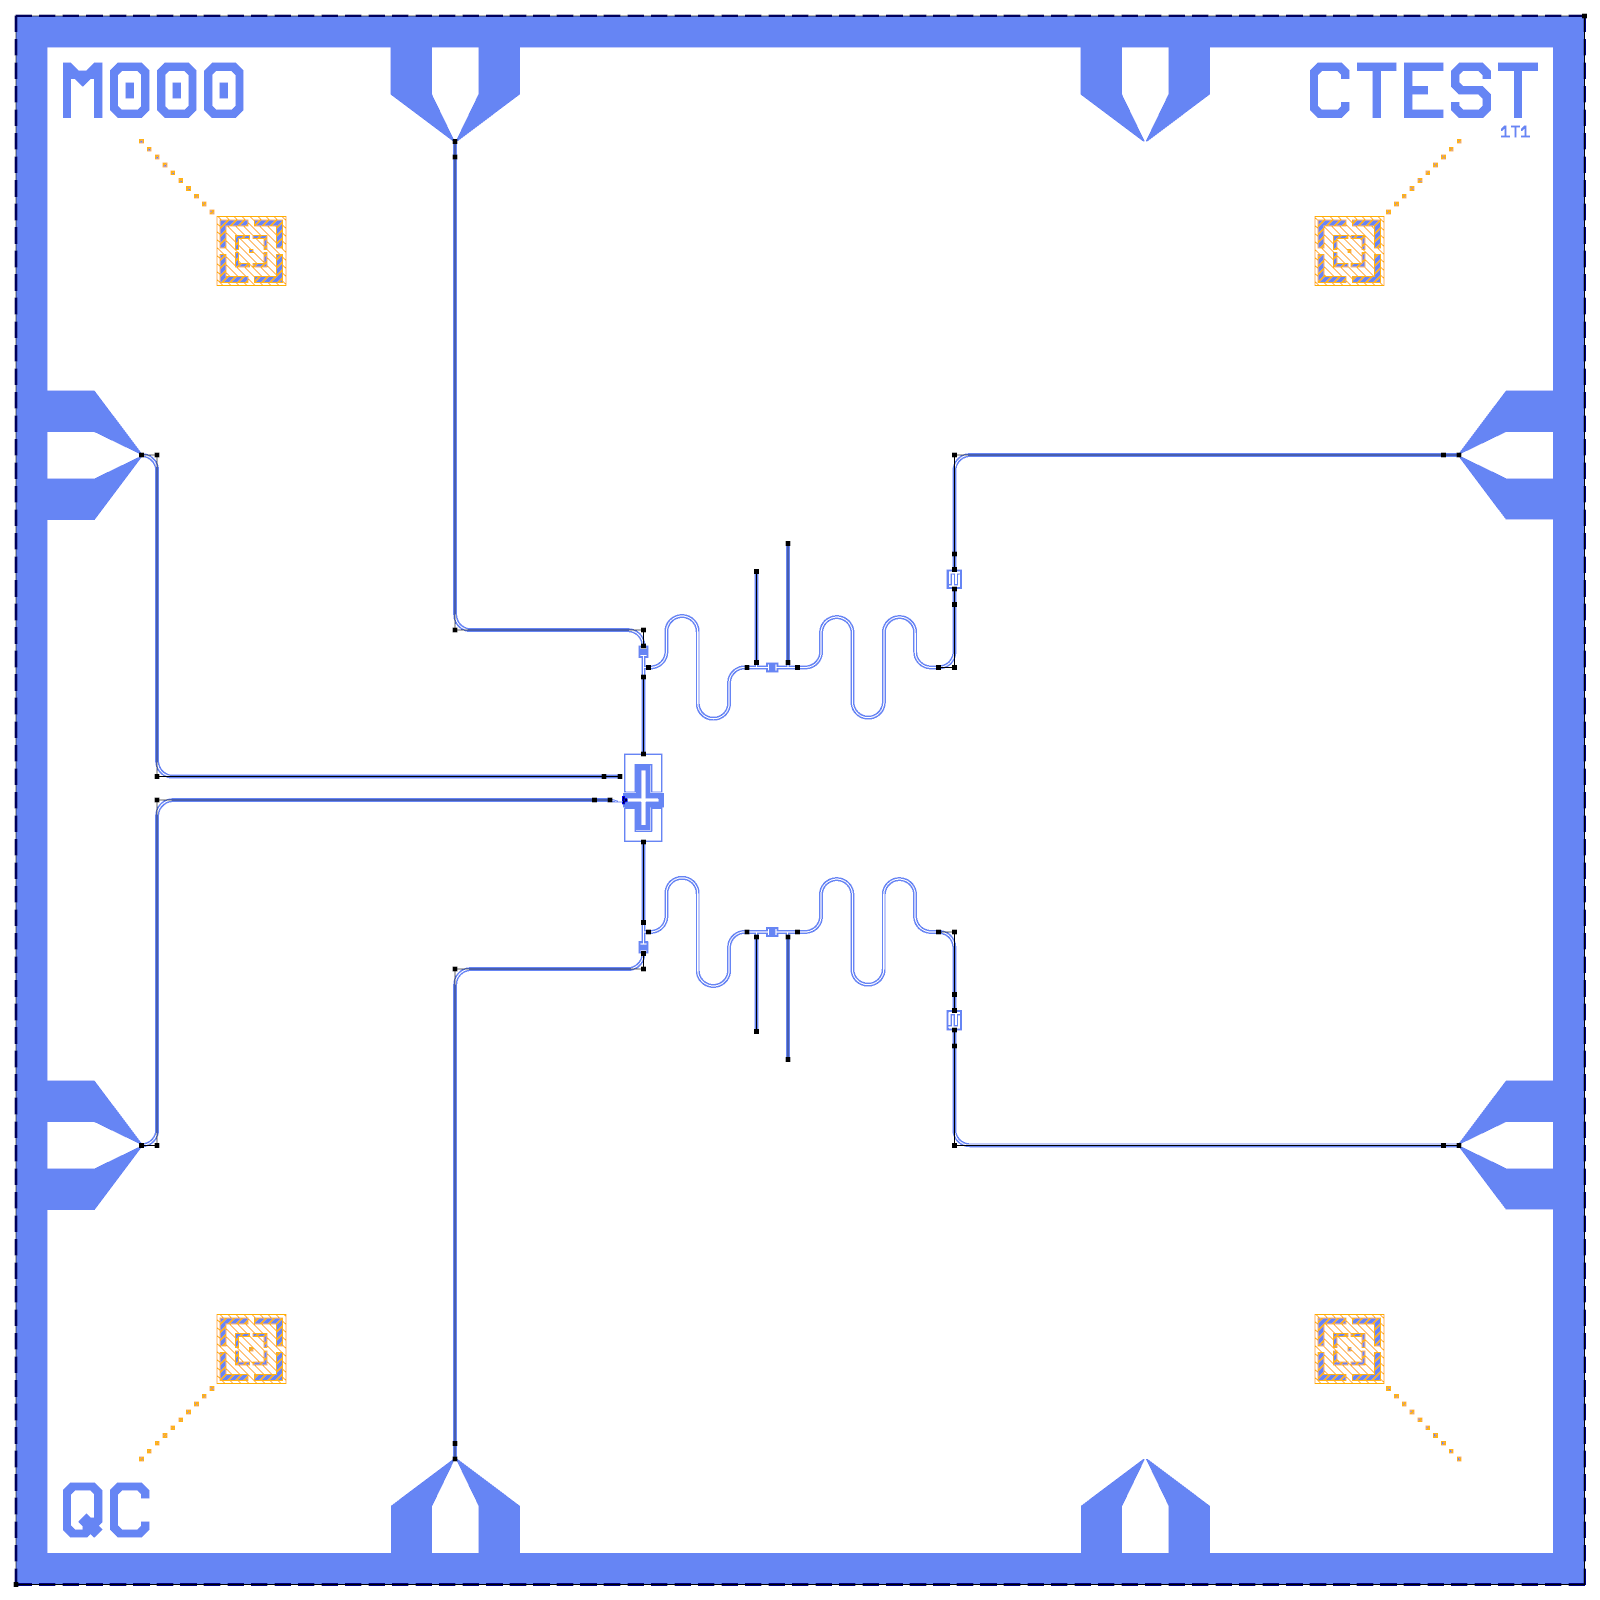

In [20]:
import klayout.db as kdb
from kqcircuits.chips.shaping import Shaping as KqcChip

ref = pya.Layout()
ref_top = ref.create_cell("ref")
ref_top.insert(pya.DCellInstArray(KqcChip.create(ref, name_brand="QC").cell_index(), pya.DTrans()))
ref.write(str(Path("build") / "shaping_kqc_original.oas"))
ly = kdb.Layout()
ly.read(str(d.out))
top = ly.top_cell()
mine = {ly.get_info(i).name: i for i in ly.layer_indexes()}
theirs = {ref.get_info(i).name: i for i in ref.layer_indexes()}
table = ["| layer | XOR area (µm²) | > 1 nm (µm²) |", "|---|---|---|"]
total = 0.0
for name in sorted(set(mine) | set(theirs)):
    if not name or name in ("refpoints", "instance_names", "ports"):
        continue
    x = ((kdb.Region(ref_top.begin_shapes_rec(theirs[name])).merged() if name in theirs else kdb.Region())
         ^ (kdb.Region(top.begin_shapes_rec(mine[name])).merged() if name in mine else kdb.Region()))
    if x.is_empty():
        continue
    total += x.area() * ref.dbu ** 2
    table.append(f"| {name} | {x.area() * ref.dbu ** 2:.3g} | {x.sized(-1).area() * ref.dbu ** 2:.3g} |")
display(Markdown("\n".join(table) + f"\n\n**Total XOR area: {total:.3g} µm²**"))
snap_file(Path("build") / "shaping_kqc_original.oas", OUT / "shaping_kqc.png", box=(-100, -100, 10100, 10100), width=420);

**Here:** the total XOR is 1.5 × 10⁸ µm², all from the expected differences: the qcc frame layers (the boundary layer covers the whole die, 1 × 10⁸ µm², plus the markers), the ground grid (2.2 × 10⁷) and its avoidance (1.3 × 10⁷), KQC's ChipFrame (dicing edge, EBL and airbridge marker shapes), the Manhattan vs trilayer SQUID layers (400–600 µm² each) and the base etch (8.9 × 10⁶ µm²: KQC's frame band and the 80 µm launcher shift).

## 15 · Summary

| | |
|---|---|
| **matches the source** | every KQC element with its parameters, positions and orientations; both chains with KQC's segment formulas and meander centre lines; the charge, flux, drive and output lines; the sim groups; KQC's whole-area ground grid |
| **differs (PDK)** | Quantcore die frame instead of KQC's ChipFrame; launchers 80 µm further in (outer etch 100 µm from the edge, `frame.pad_edge`); sapphire instead of silicon; the Quantcore trilayer SQUID (f_q ≈ 6.5 GHz instead of ≈ 5.2 GHz) |
| **simplified** | the four meanders are routes on KQC's centre lines; the LOM's tapped couplings (rough) |
| **PDK design warnings** | as listed in step 7 |
| **FEM** | 3 jobs exported (`build/jobs/shaping_*`: 1 Q3D, 2 eigenmode), not solved here |